# EN4554 Assignment 2: Convolutional Neural Networks

**Name:** _Add student name_  
**Index number:** _Add index number_  
**GitHub:** [CNN-with-CIFAR10](https://github.com/LahiruMJ11/CNN-with-CIFAR10)

This notebook contains the theory, implementations, experiments, results, and discussion for the assignment. It is designed to run on Google Colab with a T4 GPU and on a laptop with Apple MPS or CPU.

## Setup: Reproducible CIFAR-10 data pipeline

CIFAR-10 contains 60,000 RGB images of size $32\times32$ in 10 classes: 50,000 standard training images and 10,000 standard test images. Following the assignment, the standard training portion is divided into 45,000 training images and 5,000 validation images. The validation partition is used for model and hyperparameter decisions, while the standard test partition is reserved for the single final evaluation in Task 4.

To prevent data leakage, the per-channel mean and population standard deviation are calculated from only the 45,000-image training partition. If $x_{nchw}$ is a pixel scaled to $[0,1]$, the channel statistics are

$$\mu_c=\frac{1}{NHW}\sum_{n,h,w}x_{nchw},\qquad \sigma_c=\sqrt{\frac{1}{NHW}\sum_{n,h,w}x_{nchw}^2-\mu_c^2}.$$

Every training and validation image is then normalized using $\hat{x}_c=(x_c-\mu_c)/\sigma_c$. Fixed seeds make the split and data-loading order repeatable. Exact numerical results can still vary slightly across PyTorch versions and hardware backends.

In [1]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import CIFAR10

SEED = 42
DATA_ROOT = Path("./data")
TRAIN_SIZE = 45_000
VAL_SIZE = 5_000
BATCH_SIZE = 128

def seed_everything(seed: int = SEED) -> None:
    """Seed Python, NumPy, and PyTorch and request deterministic behavior."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

def select_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

seed_everything()
device = select_device()
print(f"PyTorch version: {torch.__version__}")
print(f"Selected device: {device}")

PyTorch version: 2.14.1
Selected device: mps


The device-selection order is CUDA (including a Colab T4), Apple MPS, and finally CPU. The data split is independent of the selected device because it uses a dedicated CPU generator.

In [2]:
# download=True downloads on a fresh Colab runtime and reuses the verified local archive here.
raw_dataset = CIFAR10(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

assert len(raw_dataset) == TRAIN_SIZE + VAL_SIZE
split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(raw_dataset), generator=split_generator).tolist()
train_indices = permutation[:TRAIN_SIZE]
val_indices = permutation[TRAIN_SIZE:]

assert len(train_indices) == TRAIN_SIZE
assert len(val_indices) == VAL_SIZE
assert set(train_indices).isdisjoint(val_indices)

raw_train_subset = Subset(raw_dataset, train_indices)
print(f"Original training portion: {len(raw_dataset):,}")
print(f"Training partition: {len(train_indices):,}")
print(f"Validation partition: {len(val_indices):,}")

Original training portion: 50,000
Training partition: 45,000
Validation partition: 5,000


The printed sizes and disjointness assertion confirm the required 45,000/5,000 partition. A dedicated generator with seed 42 ensures that every experiment can reuse exactly the same indices.

In [3]:
def compute_channel_statistics(dataset, batch_size: int = 512):
    """Return per-channel population mean and standard deviation."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_squared_sum = torch.zeros(3, dtype=torch.float64)
    pixel_count = 0

    for images, _ in loader:
        images = images.to(torch.float64)
        channel_sum += images.sum(dim=(0, 2, 3))
        channel_squared_sum += images.square().sum(dim=(0, 2, 3))
        pixel_count += images.shape[0] * images.shape[2] * images.shape[3]

    mean = channel_sum / pixel_count
    variance = channel_squared_sum / pixel_count - mean.square()
    std = variance.clamp_min(0).sqrt()
    return mean.to(torch.float32), std.to(torch.float32)

channel_mean, channel_std = compute_channel_statistics(raw_train_subset)
assert torch.all(channel_std > 0)

statistics_table = pd.DataFrame(
    {"mean": channel_mean.numpy(), "population std": channel_std.numpy()},
    index=["red", "green", "blue"],
)
statistics_table

,mean,population std
red,0.491656,0.247081
green,0.482334,0.243509
blue,0.446679,0.261581


The channel values differ, so a single global normalization would not centre and scale each colour channel correctly. These values were measured after the seeded split using only training pixels; validation pixels and the standard test set made no contribution.

In [4]:
normalization = transforms.Normalize(
    mean=channel_mean.tolist(),
    std=channel_std.tolist(),
)
normalized_transform = transforms.Compose([transforms.ToTensor(), normalization])

# Both subsets refer to the standard training portion; the test portion is not loaded.
normalized_dataset = CIFAR10(
    root=DATA_ROOT, train=True, download=False, transform=normalized_transform
)
train_dataset = Subset(normalized_dataset, train_indices)
val_dataset = Subset(normalized_dataset, val_indices)

num_workers = 2 if device.type == "cuda" else 0
pin_memory = device.type == "cuda"
loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
    generator=loader_generator,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
)

images, labels = next(iter(train_loader))
assert images.shape[1:] == (3, 32, 32)
assert labels.min() >= 0 and labels.max() < 10
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Example batch: images {tuple(images.shape)}, labels {tuple(labels.shape)}")

Training batches: 352
Validation batches: 40
Example batch: images (128, 3, 32, 32), labels (128,)


The loaders provide channel-first $3\times32\times32$ tensors and integer targets from 0 to 9. Training batches are shuffled reproducibly, whereas validation order remains fixed for consistent evaluation.

In [5]:
targets = np.asarray(raw_dataset.targets)
train_counts = np.bincount(targets[train_indices], minlength=10)
val_counts = np.bincount(targets[val_indices], minlength=10)
class_distribution = pd.DataFrame(
    {"training": train_counts, "validation": val_counts},
    index=raw_dataset.classes,
)
class_distribution.loc["Total"] = class_distribution.sum(axis=0)
class_distribution

,training,validation
airplane,4512,488
automobile,4488,512
bird,4468,532
cat,4529,471
deer,4529,471
dog,4486,514
frog,4493,507
horse,4500,500
ship,4496,504
truck,4499,501


The seeded random split keeps every class well represented in both partitions, with counts close to the expected 90%/10% division. The totals also independently confirm the required partition sizes.

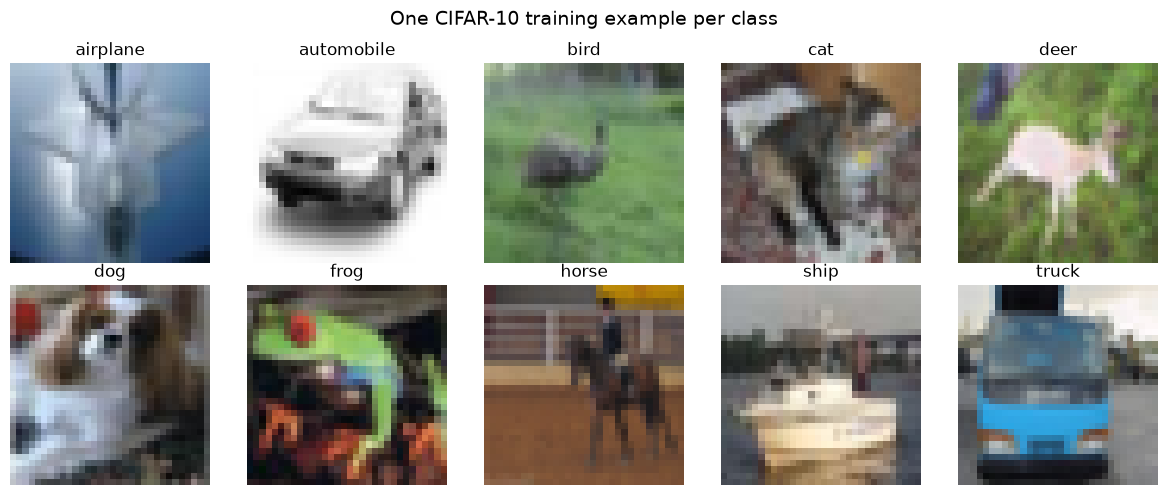

In [6]:
# Select one training example from each class without accessing test data.
example_indices = []
for class_id in range(10):
    example_indices.append(next(i for i in train_indices if targets[i] == class_id))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, (axis, dataset_index) in enumerate(zip(axes.flat, example_indices)):
    image, label = raw_dataset[dataset_index]
    axis.imshow(image.permute(1, 2, 0))
    axis.set_title(raw_dataset.classes[label])
    axis.axis("off")
fig.suptitle("One CIFAR-10 training example per class", fontsize=14)
fig.tight_layout()
plt.show()

The examples confirm that the labels and image layout were loaded correctly. CIFAR-10 images are small and visually varied, which makes classification non-trivial and motivates learning features rather than relying on individual pixels.

### Test-set policy

No `train=False` CIFAR-10 dataset or test loader is created in this setup. The final model will be selected using validation data, and the standard test set will be instantiated and evaluated exactly once in Task 4, as required by the assignment.